In [619]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pickle
import copy

In [620]:
#Dense Layer
class Dense_Layer:
    #Layer Initialization
    def __init__(self,n_inputs,n_neurons,weights_regularizer_l1=0,biases_regularizer_l1=0,weights_regularizer_l2=0,biases_regularizer_l2=0):
        #Initialize the weights and biases
        #random.randn generates samples from the standard normal distribution (mean = 0, standard deviation = 1)
        
        self.weights=0.01*np.random.randn(n_inputs,n_neurons)

        #biases are initialized to zero and making it a 2D array with shape (1,n_neurons) 
        #so that it can be added to the output of the dot product of inputs and weights
        
        self.biases=np.zeros((1,n_neurons))

        #Set regularization strength for weights and biases
        #L1 regularization penalizes large absolute weight values and encourages some weights to become exactly or approximately zero.
        #L2 regularization discourages excessively large weights by penalizing their squared values. 
        #L2 generally encourages weights to remain small rather than forcing them to become zero.


        #Include regularization in the Dense_Layer.backward() method is that regularization doesn't just add a penalty to the loss.
        #It also needs to influence how the weights and biases are updated.
        self.weights_regularizer_l1=weights_regularizer_l1
        self.biases_regularizer_l1=biases_regularizer_l1
        self.weights_regularizer_l2=weights_regularizer_l2
        self.biases_regularizer_l2=biases_regularizer_l2

    #forward pass
    def forward(self,inputs,training=False):
        self.inputs=inputs
        #calculate the output values by the inputs,weights and biases
        self.output=np.dot(inputs,self.weights)+self.biases  
    #backward pass
    def backward(self,dvalues,compute_dinputs=True):
        #Gradients on parameters
        self.dweights=np.dot(self.inputs.T,dvalues)
        self.dbiases=np.sum(dvalues,axis=0,keepdims=True)
        
        #Gradient on regularization
        #L1 on weights
        if self.weights_regularizer_l1>0:
            dl1=np.ones_like(self.weights)
            dl1[self.weights<0]=-1
            self.dweights+=self.weights_regularizer_l1*dl1

        #L2 on weights
        if self.weights_regularizer_l2>0:
            self.dweights+=2*self.weights_regularizer_l2*self.weights

        #L1 on biases
        if self.biases_regularizer_l1>0:
            dl1=np.ones_like(self.biases)
            dl1[self.biases<0]=-1
            self.dbiases+=self.biases_regularizer_l1*dl1

        #L2 on biases
        if self.biases_regularizer_l2>0:
            self.dbiases+=2*self.biases_regularizer_l2*self.biases
             
        #Gradient on values
        if compute_dinputs:
            self.dinputs=np.dot(dvalues,self.weights.T) 

    #Retrieve Parameters
    def get_parameter(self):
        return self.weights,self.biases

    #Set parameter
    def set_parameter(self,weights,biases):
        self.weights=weights
        self.biases=biases    

In [621]:
class Dropout:
    def __init__(self,rate):
        #self.rate means “keep probability”
        self.rate=1-rate

    #Forward Pass
    def forward(self,inputs,training):

        #inputs is typically shape (batch_size, n_neurons)
        self.inputs=inputs
        
        #Inference has no learning.There’s nothing for dropout’s noise to help with. 
        #Dropout only makes sense while the weights are changing. 
        #So the layer behaves differently depending on the phase, which is exactly what the training flag tells it.
        #training=True: drop and scale; training=False: pass through unchanged
        if training:
            self.binary_mask=np.random.binomial(1,self.rate,size=inputs.shape)/self.rate
            self.output=inputs*self.binary_mask
        else:
            self.binary_mask=np.ones_like(inputs)
            self.output=inputs.copy()
            

    def backward(self,dvalues):
        self.dinputs=dvalues*self.binary_mask

In [622]:
class Layer_Input:
    def forward(self,inputs,training):
        self.output=inputs

In [623]:
#Rectified Linear Unit (ReLU) Activation
class Activation_Relu:
    #Forward Pass
    def forward(self,inputs,training=False):
        #Calculate the output values from inputs
        ##Remember the inputs, backward needs them
        self.inputs=inputs
        self.output=np.maximum(0,inputs)
    
    #backward pass
    def backward(self,dvalues):
        #Since we need to modify the original variable, let's make a copy of the values first
        self.dinputs=dvalues.copy()
        #Zero gradient where input values were negative
        self.dinputs[self.inputs<=0]=0  

    def predictions(self,outputs):
            return outputs     

In [624]:
#SoftMax Activation
class Activation_Softmax:
    #Forward Pass
    def forward(self,inputs,training=False):
        #Get Unnormalized Probabilities
        #After subtracting the max, the largest value in each row becomes 0.
        #so the biggest exponent is e⁰ = 1 and everything else is between 0 and 1. No overflow

        exp_values=np.exp(inputs-np.max(inputs,axis=1,keepdims=True))
        
        #Normalize them for each sample
        probabilities=exp_values/np.sum(exp_values,axis=1,keepdims=True)

        #calculate the normalized probalities
        self.output=probabilities

    #backward pass
    def backward(self,dvalues):

        #create uninitialized array
        # The ​np.empty_like​ method creates an empty and uninitialized array. 
        # Uninitialized means that we can expect it to contain meaningless values, but we’ll set all of them shortly anyway
        self.dinputs=np.empty_like(dvalues)

        #enumerate outputs and gradients
        for index,(single_output,single_dvalues) in enumerate(zip(self.output,dvalues)):

            #flatten output array
            single_output=single_output.reshape(-1,1)

            #calculate Jacobian matrix of the output
            jacobian_matrix=np.diagflat(single_output)-np.dot(single_output,single_output.T)
            
            #calculate sample-wise gradient and add it to the array of sample gradients
            self.dinputs[index]=np.dot(jacobian_matrix,single_dvalues)
            #So these are the gradients of the loss with respect to Softmax’s  inputs for 1 sample.
    def predictions(self,outputs):
        return np.argmax(outputs,axis=1)

In [625]:
class Sigmoid_Activation:
    def forward(self,inputs,training=False):
        #save inputs and calculate the output of the sigmoid function
        #The formula for the sigmoid function is: sigmoid(x) = 1 / (1 + e^(-x))
        self.inputs=inputs
        self.output=1/(1+np.exp(-inputs))

        
    def backward(self,dvalues):
        #The derivative of the sigmoid function is given by the formula: sigmoid'(x) = sigmoid(x) * (1 - sigmoid(x)).
        self.dinputs=dvalues*(1-self.output)*self.output

    def predictions(self,outputs):
        return (outputs>0.5)*1


In [626]:
#Linear Activation Function
#How will this class work?
#------>Dense layer output -> Activation_Linear.forward -> loss
#------>loss.backward -> Activation_Linear.backward -> Dense layer backward
class Activation_Linear:
    #Forward pass
    def forward(self, inputs,training=False):
        #we want the network to be able to output any number, not a probability or a class
        self.output = inputs

    #Backward pass
    def backward(self, dvalues):
        #dvalues is the gradient coming back from the loss: how much the loss changes with respect to this layer’s output
        self.dinputs = dvalues.copy()

    def predictions(self,outputs):
        #Linear Activation Function always gives the output as the predicted number
        return outputs

In [627]:
class Optimizer_SGD:
    def __init__(self,learning_rate=1,decay=0,momentum=0):

        #Stores the learning rate, which controls how big each step is. It defaults to 1
        #Iterations answers “how far along is training?” It starts at 0 and goes up by 1 every step, so the optimizer always knows what step it’s on.
        #Decay answers “how fast should the rate shrink as training goes on?” You pick it once and it never changes
        #Momentum answers “how much should we consider the previous update when making the current one?” You pick it once and it never changes

        self.learning_rate=learning_rate
        self.current_learning_rate=learning_rate
        self.decay=decay
        self.iteration=0

        #Momentum determines how much of the previous update contributes to the current update.
        self.momentum=momentum

    def pre_update_params(self):
        #if self.decay: means “only do this if decay is not zero
        #line is a shortcut for if self.decay != 0:
        if self.decay:
            self.current_learning_rate=self.learning_rate*(1/(1+self.decay*self.iteration))


    #Positive gradient: raising the weight raises the loss, so it goes down.
    #Negative gradient: raising the weight lowers the loss, so it goes up.
    
    def update_params(self,layer):
        #Layer contains the weights, biases, and their gradients. The optimizer updates them based on the gradients and learning rate.

        #Momentum enabled.
        if self.momentum:

            #The following code means:does this layer already have a variable called weight_momentums
            #The first iteration of training.There is no previous update yet.Therefore, we need to create an initial momentum value.

            if not hasattr(layer,'weight_momentums'):
            #if the layer does not contain momentum arrays, create them filled with zeros

                # every weights and biases needs its own momentum value.So we are creating an array of zeros with the same shape as the weights and biases.
                #This initialization happens only once for each layer. In subsequent iterations, the previous momentum arrays are reused.

                layer.weight_momentums=np.zeros_like(layer.weights)
                layer.bias_momentums=np.zeros_like(layer.biases)

            #build weight updates with momentum-take previous updates into account
            #update weight and bias momentums

            #The formula:----> current weights update = momentum * previous weights update - learning rate * current weight gradient
            #[momentum * previous weights update]--->This takes the previous weight update and multiplies it by the momentum coefficient.
            
            weight_updates=self.momentum*layer.weight_momentums-(self.current_learning_rate*layer.dweights)

            #we need to remember the latest update, not the update from two or three iterations ago.So we store the current update in the layer’s weight_momentums attribute.
            layer.weight_momentums=weight_updates

            #The formula:----> current biases update = momentum * previous biases update - learning rate * current bias gradient
            bias_updates=self.momentum*layer.bias_momentums-(self.current_learning_rate*layer.dbiases)
            layer.bias_momentums=bias_updates   
        
        #Momentum disabled: using ordinary SGD.
        else:
            #The formula:----> current weights update = - learning rate * current weight gradient
            weight_updates=-self.current_learning_rate*layer.dweights
            bias_updates=-self.current_learning_rate*layer.dbiases

        layer.weights+=weight_updates
        layer.biases+=bias_updates

    def post_update_params(self):
        self.iteration+=1
        

In [628]:
class Optimizer_Adagrad:
    #Adagrad doesn't have a momentum coefficient.
    #It has a decay rate, which is the same as in SGD.
    #It also has an epsilon value, which is a small number that prevents division by zero when normalizing the gradients.
    

    def __init__(self,learning_rate=1,decay=0,epsilon=1e-7):
        self.learning_rate=learning_rate
        self.current_learning_rate=learning_rate
        self.decay=decay
        self.iteration=0
        self.epsilon=epsilon

    def pre_update_params(self):

        #This decay is not unique to Adagrad. 
        #It is a general learning-rate scheduling mechanism that your optimizer implements separately from Adagrad's adaptive mechanism.
        
        if self.decay:

            #It gradually reduces the learning rate as training progresses.
            #The formula for the decayed learning rate is: current_learning_rate = initial_learning_rate * (1 / (1 + decay * iteration number))
            
            self.current_learning_rate=self.learning_rate*(1/(1+self.decay*self.iteration))

    def update_params(self,layer):

        #Momentum remembers previous parameter updates.
        #Adagrad remembers the sum of previous squared gradients.
        #If the layer does not contain cache arrays, create them filled with zeros.
        #Every weights and biases needs its own momentum value.
        #So we are creating an array of zeros with the same shape as the weights and biases.

        if not hasattr(layer,'weight_cache'):
            layer.weight_cache=np.zeros_like(layer.weights)
            layer.bias_cache=np.zeros_like(layer.biases)

        #Update cache with squared current gradients.
        #Unlike momentum, Adagrad does not reduce the influence of older gradients.It accumulates the sum of squared gradients over time. 
        #This means that as training progresses, the cache values grow larger, which in turn reduces the effective learning rate for parameters that have received large gradients in the past.
        
        layer.weight_cache+=layer.dweights**2
        layer.bias_cache+=layer.dbiases**2

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights+=-self.current_learning_rate*layer.dweights/(np.sqrt(layer.weight_cache)+self.epsilon)
        layer.biases+=-self.current_learning_rate*layer.dbiases/(np.sqrt(layer.bias_cache)+self.epsilon)

    def post_update_params(self):
        self.iteration+=1

In [629]:
class Optimizer_RMSprop:
    #RMSprop is similar to Adagrad, but it introduces a decay factor for the cache, which helps to prevent the learning rate from decreasing too quickly.
    #It has a decay rate, which is the same as in SGD.
    #It also has an epsilon value, which is a small number that prevents division by zero when normalizing the gradients.
    ##The formula is---> C_t=rho* C_{t-1}+(1-\rho)*g_t^2
    #This formula gives more importance to recent gradients and gradually reduces the influence of older gradients.

    def __init__(self,learning_rate=0.001,decay=0,rho=0.9,epsilon=1e-7):
        self.learning_rate=learning_rate
        self.current_learning_rate=learning_rate
        self.decay=decay
        self.iteration=0
        self.rho=rho
        self.epsilon=epsilon

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate=self.learning_rate*(1/(1+self.decay*self.iteration))

    def update_params(self,layer):
        if not hasattr(layer,'weight_cache'):
            layer.weight_cache=np.zeros_like(layer.weights)
            layer.bias_cache=np.zeros_like(layer.biases)

        # Update cache with squared current gradients and apply decay factor
        layer.weight_cache=self.rho*layer.weight_cache+(1-self.rho)*layer.dweights**2
        layer.bias_cache=self.rho*layer.bias_cache+(1-self.rho)*layer.dbiases**2

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights+=-self.current_learning_rate*layer.dweights/(np.sqrt(layer.weight_cache)+self.epsilon)
        layer.biases+=-self.current_learning_rate*layer.dbiases/(np.sqrt(layer.bias_cache)+self.epsilon)

    def post_update_params(self):
        self.iteration+=1

In [630]:
class Optimizer_Adam:

    #Adam combines the benefits of both momentum and Adagrad. 
    #The main idea: Adam combines two ideas you've already learned:
    #1. Momentum: remembers the direction of previous gradients.
    #2. RMSprop: remembers the magnitude of previous squared gradients and uses that information to adjust the learning rate.

    def __init__(self,learning_rate=0.001,decay=0,epsilon=1e-7,beta_1=0.9,beta_2=0.999):
        self.learning_rate=learning_rate
        self.current_learning_rate=learning_rate
        self.decay=decay
        self.iteration=0
        self.epsilon=epsilon

        #beta_1	Controls how much Adam remembers previous gradients (Momentum).
        self.beta_1=beta_1
        
        #beta_2	Controls how much Adam remembers previous squared gradients (RMSprop).
        self.beta_2=beta_2

    def pre_update_params(self):

        #Same learning-rate decay mechanism we have seen in SGD, Adagrad, and RMSprop.
        if self.decay:
            self.current_learning_rate=self.learning_rate*(1/(1+self.decay*self.iteration))

    def update_params(self,layer):
        if not hasattr(layer,'weight_cache'):

            #Adam needs four separate arrays
            #weight_momentums stores momentum for weights.
            #weight_cache stores squared-gradient information for weights.
            #bias_momentums	stores momentum for biases.
            #bias_cache	stores squared-gradient information for biases.

            layer.weight_momentums=np.zeros_like(layer.weights)
            layer.weight_cache=np.zeros_like(layer.weights)
            layer.bias_momentums=np.zeros_like(layer.biases)
            layer.bias_cache=np.zeros_like(layer.biases)

        # Update momentum with current gradients
        #This is the Momentum component
        layer.weight_momentums=self.beta_1*layer.weight_momentums+(1-self.beta_1)*layer.dweights
        layer.bias_momentums=self.beta_1*layer.bias_momentums+(1-self.beta_1)*layer.dbiases

        # Get corrected momentum
        weight_momentums_corrected=layer.weight_momentums/(1-self.beta_1**(self.iteration+1))
        bias_momentums_corrected=layer.bias_momentums/(1-self.beta_1**(self.iteration+1))

        # Update cache with squared current gradients
        #This is the RMSprop component
        layer.weight_cache=self.beta_2*layer.weight_cache+(1-self.beta_2)*layer.dweights**2
        layer.bias_cache=self.beta_2*layer.bias_cache+(1-self.beta_2)*layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected=layer.weight_cache/(1-self.beta_2**(self.iteration+1))
        bias_cache_corrected=layer.bias_cache/(1-self.beta_2**(self.iteration+1))

        # Vanilla SGD parameter update + normalization
        layer.weights-=self.current_learning_rate*weight_momentums_corrected/(np.sqrt(weight_cache_corrected)+self.epsilon)
        layer.biases-=self.current_learning_rate*bias_momentums_corrected/(np.sqrt(bias_cache_corrected)+self.epsilon)

    def post_update_params(self):
        self.iteration+=1

In [631]:
#Common Loss Function Class
class Loss:
    #calculate two things----->
    # 1. How far are the model's predictions from the actual answers? 
    # 2. How much are the weights and biases being penalized for being too large?

    #Calculate the data and regularization losses
    #Given model output and ground truth values
    #Set trainable layers
    #remember_trainable_layers​ method  “tells” the loss object which layers in the ​Model​ object are trainable
    def remember_trainable_layers(self,trainable_layers):
        self.trainable_layers=trainable_layers

    def regularization_loss(self):

        #0 by default
        regularization_loss=0

        for layer in self.trainable_layers:
            if layer.weights_regularizer_l1 > 0:
                regularization_loss += layer.weights_regularizer_l1 * np.sum(np.abs(layer.weights))
            if layer.biases_regularizer_l1 > 0:
                regularization_loss += layer.biases_regularizer_l1 * np.sum(np.abs(layer.biases))
            if layer.weights_regularizer_l2 > 0:
                regularization_loss += layer.weights_regularizer_l2 * np.sum(layer.weights ** 2)
            if layer.biases_regularizer_l2 > 0:
                regularization_loss += layer.biases_regularizer_l2 * np.sum(layer.biases ** 2)
        return regularization_loss
      
    #This method calculates the average data loss
    def calculate(self,output,y,*,include_regularization=False):

        #Calculate the sample loss
        #This Loss class doesn't define its own forward() method. Instead, a child class(loss_CategoricalCrossentropy) implements it.
        sample_losses=self.forward(output,y)

        #calculate the mean loss
        data_loss=np.mean(sample_losses)

        #Add accumulated loss and sample count
        self.accumulated_sum+=np.sum(sample_losses)
        self.accumulated_count+=len(sample_losses)

        #If regularization is not added, only return loss
        if not include_regularization:
            return data_loss
        
        #Other return both
        return data_loss,self.regularization_loss() 
        
    def calculate_accumulated(self,*,include_regularization=False):
        data_loss=self.accumulated_sum/self.accumulated_count
        
        #If we dont include regularization loss,we just calculate data_loss
        if not include_regularization:
            return data_loss
        return data_loss,self.regularization_loss()
    
    def new_pass(self):
        self.accumulated_sum=0
        self.accumulated_count=0
    

In [632]:
#Cross Entropy Loss for Categorical Classification
class Loss_CategoricalCrossentropy(Loss):
    #forward Pass
    def forward(self,y_pred,y_true):
        #restrict (limit) the values of y_prediction within a specified minimum and maximum range
        y_pred_clipped=np.clip(y_pred,1e-7,1-1e-7)
        #for categorical labels
        if len(y_true.shape)==1:
            correct_confidences=y_pred_clipped[range(len(y_pred)),y_true]
        elif len(y_true.shape)==2:
            product=y_pred_clipped*y_true
            correct_confidences=np.sum(product,axis=1)
        neg_log_likelihood=-np.log(correct_confidences)
        return neg_log_likelihood  
        
    #Backward Pass

    #It computes how much the loss changes w.r.t each predicted probability, so that gradient can flow back into the earlier layers.
    #the loss is L = -Σ y_true[i] · log(y_pred[i]). 
    #Its derivative with respect to each predicted probability is -y_true[i] / y_pred[i]

    def backward(self,y_pred,y_true):

        #number of samples
        #samples = len() gives the batch size
        
        samples=len(y_pred)
        
        #number of labels in every sample
        labels=len(y_pred[0])

        #y_true can come in two forms: sparse class indices like [0, 2, 1] (1D), or one-hot vectors (2D). 
        #The formula needs one-hot, so if it’s 1D, it converts it. np.eye(labels) builds an identity matrix
        #  Thus indexing it with y_true picks one row per sample.

        if len(y_true.shape)==1:
            y_true=np.eye(labels)[y_true]
        
        # calculate the gradient
        # dinputs answers the question: if I nudge each predicted probability a little, how much does the loss change?
        # y_true is one-hot, everything is 0 except at the true class. 
        # For a prediction [0.7, 0.2, 0.1] with true class 0, the result is [-1/0.7, 0, 0] ≈ [-1.43, 0, 0]. 
        # The negative sign means “increase this probability to lower the loss”, and the smaller the predicted probability, the stronger the push.
        
        self.dinputs=-y_true/y_pred
        
        #normalize the gradient
        #The loss you report is the mean over the batch, so its gradient gets a 1/samples factor. 
        # This also keeps the gradient size independent of batch size, which makes the learning rate behave consistently.

        self.dinputs=self.dinputs/samples     

In [633]:
class Activation_Softmax_Loss_CategoricalCrossentropy():
    def backward(self,dvalues,y_true):
        #number of samples in a batch
        samples=len(dvalues)

        #if labels are one-hot encoded, turn them into discrete values
        #This makes sure y_true is always a 1D array of class numbers, no matter which label format we started with.
        #y_true.shape is a tuple of the array’s dimensions, and len() of it tells you how many dimensions there are
                
        if len(y_true.shape)==2:
            y_true=np.argmax(y_true,axis=1)
        #copy so we can safely modify

        self.dinputs=dvalues.copy()
        
        #calculate gradient
        #samples supplies the row numbers, y_true supplies the column numbers.
        # together they point at one cell per row, the true class, which is where ŷ − y differs from ŷ.
        #the gradient of softmax + cross-entropy is ŷ − y, and y is a one-hot vector 
        #so “minus y” means “minus 1 at the true class, minus 0 everywhere else.

        self.dinputs[range(samples),y_true]-=1
        
        #normalize gradient by mean of samples
        # This ensures that the gradient is averaged across all samples in the batch, making it independent of the batch size.
        
        self.dinputs=self.dinputs/samples
        #backward doesn’t return anything. It saves its result as an attribute.

In [634]:
#Cross Entropy Loss for Binary Classification
class Loss_BinaryCrossentropy(Loss):
    def forward(self,y_pred,y_true):
        #restrict (limit) the values of y_prediction within a specified minimum and maximum range
        y_pred_clipped=np.clip(y_pred,1e-7,1-1e-7)
        #calculate sample-wise loss
        sample_losses=-(y_true*np.log(y_pred_clipped)+(1-y_true)*np.log(1-y_pred_clipped))
        sample_losses=np.mean(sample_losses,axis=-1)
        return sample_losses

    def backward(self,dvalues,y_true):
        #number of samples
        samples=len(dvalues)
        #number of outputs in every sample
        outputs=len(dvalues[0])
        #clip data to prevent division by 0
        clipped_dvalues=np.clip(dvalues,1e-7,1-1e-7)
        #calculate gradient
        self.dinputs=-(y_true/clipped_dvalues-(1-y_true)/(1-clipped_dvalues))/outputs
        #normalize gradient
        self.dinputs=self.dinputs/samples

In [635]:
#Mean Squared Error Loss
#How will this class work?
#------>Dense layer output -> Activation_Linear.forward -> loss.forward -> loss.backward -> Activation_Linear.backward -> Dense layer backward
class Loss_MeanSquaredError(Loss):
    #Forward pass
    def forward(self, y_pred, y_true):
        #calculate the sample losses
        sample_losses = np.mean((y_true - y_pred) ** 2, axis=-1)
        return sample_losses

    #Backward pass
    def backward(self, dvalues, y_true):
        #number of samples
        samples = len(dvalues)
        #number of outputs in every sample
        #The code includes outputs so the class works in general, including models that predict several values per sample
        #If you only ever predict one value per sample, then yes, samples alone is enough. 
        #But Keeping outputs just makes the loss correct for the multi-output case too.
        outputs = len(dvalues[0])
        #gradient on values
        self.dinputs = -2 * (y_true - dvalues) / outputs
        #normalize the gradient
        self.dinputs = self.dinputs / samples

In [636]:
class MeanAbsoluteError(Loss):
    #Forward pass
    def forward(self, y_pred, y_true):
        #calculate the sample losses
        sample_losses = np.mean(np.abs(y_true - y_pred), axis=-1)
        return sample_losses

    #Backward pass
    def backward(self, dvalues, y_true):
        #number of samples
        samples = len(dvalues)
        #number of outputs in every sample
        outputs = len(dvalues[0])
        #gradient on values
        self.dinputs = -np.sign(y_true - dvalues) / outputs
        #normalize the gradient
        self.dinputs = self.dinputs / samples

In [637]:
class Accuracy:
    def calculate(self,predictions,y):

        #Get comparison results
        comparisons=self.compare(predictions,y)

        #Calculate the accuracy for this batch
        accuracy=np.mean(comparisons)

        #Add accumulated correct predictions
        self.accumulated_sum+=np.sum(comparisons)
        self.accumulated_count+=len(comparisons)
        
        return accuracy
    
    #calculates accumulated accuracy
    def calculate_accumulated(self):

        #calculate an accuracy
        accuracy=self.accumulated_sum/self.accumulated_count

        #return the accuracy
        return accuracy
    
    #Reset variables for accumulated accuracy
    def new_pass(self):
        self.accumulated_sum=0
        self.accumulated_count=0

In [638]:
class Accuracy_Regression(Accuracy):
    def __init__(self):
        self.precision=None
    def init(self,y,reinit=False):
        if self.precision is None or reinit:
            self.precision=np.std(y)/250
    def compare(self,predictions,y):
        return np.absolute(predictions-y)<self.precision

In [639]:
class Accuracy_Categorical(Accuracy):
    #No initialization is needed
    def init(self,y):
        pass
    def compare(self,predictions,y):
        if len(y.shape)==2:
            # one-hot -> class index
            y=np.argmax(y,axis=1)
        return predictions==y

In [640]:
class Model:
    def __init__(self):
        #create a list of network object
        self.layer=[]
        self.softmax_classifier_output=None

    #Add objects to the model
    def add(self,layer):
        self.layer.append(layer)
        
    def set(self,*,loss=None,optimizer=None,accuracy=None):
        
        if loss is not None:
            self.loss=loss
        if optimizer is not None:
            self.optimizer=optimizer
        if accuracy is not None:
            self.accuracy=accuracy
    
    #Finalize the model
    def finalize(self):
        #create and set the model
        self.input_layer=Layer_Input()

        #Count all the objcts
        layer_count=len(self.layer)

        #Initialize a list containing trainable layers
        self.trainable_layers=[]

        #Iterate the objects
        for i in range(layer_count):

            #if it is the first layer, previous layer object is the input layer
            if i==0:
                self.layer[i].previous=self.input_layer
                self.layer[i].next=self.layer[i+1]

            #All the layers except the first and the last one
            elif i<layer_count-1:
                self.layer[i].previous=self.layer[i-1]
                self.layer[i].next=self.layer[i+1]

            #For the last layer, the next layer would be the loss function
            else:
                self.layer[i].previous=self.layer[i-1]
                self.layer[i].next=self.loss
                self.output_layer_activation=self.layer[i]

            #if layer contains an attribite called 'weights' its a trainable layer
            #Add this trainable layer to the list of trainable layers
            if hasattr(self.layer[i],'weights'):
                self.trainable_layers.append(self.layer[i])

        #Update loss object with trainable layers
        if self.loss is not None:
            self.loss.remember_trainable_layers(self.trainable_layers)

        #if output activation is a softmax and loss function is a categorical cross-entropy
        # create an obejct of combined activation and loss function for faster gradient calculation 
        if isinstance(self.layer[-1],Activation_Softmax) and isinstance(self.loss,Loss_CategoricalCrossentropy):

            #create an object of combined activation and loss functions
            self.softmax_classifier_output=Activation_Softmax_Loss_CategoricalCrossentropy()


    #Train the model
    #None means “no value was given.”
    def train(self,X,y,*,epoch=1,print_interval=1,validation_data=None,batch_size=None):

        #Initialize accuracy
        self.accuracy.init(y)
        
        #Default value setup if batch size is not defines,one epoch-->Whole data
        train_steps=1

        #If validation Data is passed
        if validation_data is not None:
            validation_steps=1

            #For better visibility
            X_val,y_val=validation_data

        #calculate number of steps
        if batch_size is not None:
            train_steps=len(X)//batch_size
            if train_steps*batch_size<len(X):
                train_steps+=1
            if validation_data is not None:
                validation_steps=len(X_val)//batch_size
                if validation_steps*batch_size<len(X_val):
                    validation_steps+=1

        #Main Training Loop
        for epoch in range(1,epoch+1):

            #Print the epoch number
            print(f'epoch:{epoch}')

            #Reset accumulated values in loss and accuracy objects
            self.loss.new_pass()
            self.accuracy.new_pass()

            #iterate over steps
            for step in range(train_steps):
                #If the batch_size is not set,train use one step and full dataset
                if batch_size is None:
                    batch_X=X
                    batch_y=y
                
                #otherwise slice a batch
                else:
                    batch_X=X[step*batch_size:(step+1)*batch_size]
                    batch_y=y[step*batch_size:(step+1)*batch_size]
                
                #perform the forward pass
                output=self.forward(batch_X,training=True)
                
                #calculate loss
                data_loss,regularization_loss=self.loss.calculate(output,batch_y,include_regularization=True)
                loss=data_loss+regularization_loss

                #Get predictions and calculate the accuracy
                predictions=self.output_layer_activation.predictions(output)
                accuracy=self.accuracy.calculate(predictions,batch_y)
                
                #Perform backward Pass
                self.backward(output,batch_y)
                
                #Optimize (Update Parameters)
                self.optimizer.pre_update_params()
                for layer in self.trainable_layers:
                    self.optimizer.update_params(layer)
                self.optimizer.post_update_params()

                #Print the whole scenerio
                if not step % print_interval or step==train_steps-1:
                    print(f'step: {step}, '+ 
                        f'acc: {accuracy:.3f}, '+ 
                        f'loss:{loss:.3f}('+ 
                        f'data_loss:{data_loss:.3f}, '+ 
                        f'reg_loss: {regularization_loss:.3f}), '+ 
                        f'lr: {self.optimizer.current_learning_rate}') 

            #Get and print epoch loss and accuracy
            epoch_data_loss,epoch_regularization_loss=self.loss.calculate_accumulated(include_regularization=True)
            epoch_loss=epoch_data_loss+epoch_regularization_loss
            epoch_accuracy=self.accuracy.calculate_accumulated()
            print(f'training,'+ 
                    f'acc: {epoch_accuracy:.3f}, '+ 
                    f'loss:{epoch_loss:.3f}('+ 
                    f'data_loss:{epoch_data_loss:.3f}, '+ 
                    f'reg_loss: {epoch_regularization_loss:.3f}), '+ 
                    f'lr: {self.optimizer.current_learning_rate}')
        
            #if there is validation data
            if validation_data is not None:

                #Evaluate the problem
                self.evaluate(*validation_data,batch_size=batch_size)

    #Evaluates the model
    def evaluate(self,X_val,y_val,*,batch_size=None):

        #Default value for step if batch size is not defined
        validation_steps=1

        #calculate the number of steps
        if batch_size is not None:
            validation_steps=len(X_val)//batch_size
            if validation_steps*batch_size<len(X_val):
                validation_steps+=1

        #reset accumulated values in loss and accuracy objects
        self.loss.new_pass()
        self.accuracy.new_pass()

        #Iterate over steps
        for step in range(validation_steps):

            #If batch_size is not set,train using one step and full datset
            if batch_size is None:
                batch_X=X_val
                batch_y=y_val

            #otherwise slice a batch
            else:
                batch_X=X_val[step*batch_size:(step+1)*batch_size]
                batch_y=y_val[step*batch_size:(step+1)*batch_size]

            #perform the forward pass
            output=self.forward(batch_X,training=False)

            #Calculate the loss
            self.loss.calculate(output,batch_y)

            #Get predictions and calculate an accuracy
            predictions=self.output_layer_activation.predictions(output)
            self.accuracy.calculate(predictions,batch_y)

        #Get and print validation loss and accuracy
        validation_loss=self.loss.calculate_accumulated()
        validation_accuracy=self.accuracy.calculate_accumulated()

        #print a summary
        print(f'validation,'+
            f'acc:{validation_accuracy:.3f},'+
            f'loss:{validation_loss:.3f}')        

                
    #Peform the forward Pass
    def forward(self,X,training):

        #Call forward method from the input layer
        #Its forward just does self.output = inputs, so now input_layer.output holds our data X
        self.input_layer.forward(X,training)

        #Visits each layer in the order it was added
        for layer in self.layer:
            #Each layer class has its own forward method
            layer.forward(layer.previous.output,training)

        #"layer" is now the last object from the list,
        # return its output
        return layer.output
    
    def backward(self,output,y):

        #If softmax classifer is not none
        if self.softmax_classifier_output is not None:

            #First Call Backward method on the combined function
            self.softmax_classifier_output.backward(output,y)

            #Since we will not call backward method of the last layer which is softmax activation
            self.layer[-1].dinputs=self.softmax_classifier_output.dinputs

            #Call backward method going through all the objects but last in reversed order passing dinputs as parameter
            for layer in reversed(self.layer[:-1]):
                layer.backward(layer.next.dinputs)
            return
        
        #First: Call Backward Method in the loss
        #And then this will set the dinputs properties
        self.loss.backward(output,y)

        #call backward method going through all the objects in reversed order passing dinputs as a parameter
        for layer in reversed(self.layer):

            #In the forward pass, each layer read layer.previous.output. Now it’s mirrored: each layer reads layer.next.dinputs
            layer.backward(layer.next.dinputs)

    #Copying a trained model’s learned numbers out of one model (get) and pasting them into another (set)

    #Get the parameters from trainable layers
    def get_parameter(self):

        #create a list of parameters
        parameters=[]

        for layer in self.trainable_layers:
            parameters.append(layer.get_parameter())

        #Return a list
        return parameters

    #Update the model with new parameters
    def set_parameter(self,parameters):

        #Iterate over the parameters and layers
        for parameter_set,layer in zip(parameters,self.trainable_layers):
            layer.set_parameter(*parameter_set)

    #Save the parameters in a file
    def save_parameter(self,path):

        #Open a file in the binary-write mode and save parameters to it.
        with open(path,'wb') as f:
            pickle.dump(self.get_parameter(),f)

    #Load the parameter file
    def load_parameter(self,path):

        #Open file in the binary-write mode and load weights and update trainable layers
        with open(path,'rb') as f:
            self.set_parameter(pickle.load(f))

    #Save the model
    def save(self,path):

        #Make a deep copy of current model instance
        model=copy.deepcopy(self)

        #Reset accumulated values in loss and accuracy objects
        model.loss.new_pass()
        model.accuracy.new_pass()

        #Remove data from input layer and gradients from loss object
        model.input_layer.__dict__.pop('output',None)
        model.loss.__dict__.pop('dinputs',None)

        #For each layer remove inputs,output and dinput properties
        for layer in model.layer:
            for property in ['inputs','output','dinputs','dweights','dbiases']:
                layer.__dict__.pop(property,None)
        
        #open a file in the binary-write mode and save the model
        with open(path,'wb') as f:
            pickle.dump(model,f)
    
    #no object is needed
    #Loads and returns a model
    @staticmethod
    def load(path):

        #Open file with a binary-read mode and load a model
        with open(path,'rb') as f:
            model=pickle.load(f)

        #Return the model
        return model
    
    #Predict on the samples
    def predict(self,X,*,bacth_size=None):

        #Default value if batch size is not being set
        prediction_steps=1

        #Calculate the number of steps
        if bacth_size is not None:
            prediction_steps=len(X)//batch_size

            #Dividing rounds down 
            if prediction_steps*batch_size<len(X):
                prediction_steps+=1
        
        #Model outputs
        output=[]
        
        #Iterate over steps
        for step in range(prediction_steps):

            #If batch_size is not defined,train using one step and full dataset
            if bacth_size is None:
                batch_X=X

            #Otherwise slice a batch
            else:
                batch_X=X[step*batch_size:(step+1)*batch_size]
            
            #perform the forward pass
            batch_output=self.forward(batch_X,training=False)

            #Append predictions
            output.append(batch_output)

            #return result
            return np.vstack(output)


In [641]:
df_train=pd.read_csv('data/fashion-mnist_train.csv')

In [642]:
df_test=pd.read_csv('data/fashion-mnist_test.csv')

In [643]:
df_train.tail()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
59995,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,1,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,8,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59999,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [644]:
y_train=df_train['label']
y_test=df_test['label']
x_train=df_train.iloc[:,1:]
x_test=df_test.iloc[:,1:]

In [645]:
y_train

0        2
1        9
2        6
3        0
4        3
        ..
59995    9
59996    1
59997    8
59998    8
59999    7
Name: label, Length: 60000, dtype: int64

In [646]:
x_train=(x_train.astype(np.float32)-127.5)/127.5
x_test=(x_test.astype(np.float32)-127.5)/127.5

In [647]:
x_train

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0
1,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0
2,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-0.960784,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-0.764706,-0.662745,-1.000000,-1.0,-1.0,-1.0,-1.0
3,-1.0,-1.0,-1.0,-0.992157,-0.984314,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-0.976471,-1.000000,-1.000000,-1.000000,-1.000000,-0.992157,-1.0,-1.0,-1.0,-1.0
4,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0
59996,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-0.427451,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0
59997,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,0.254902,0.270588,0.278431,0.058824,-0.262745,-1.000000,-1.0,-1.0,-1.0,-1.0
59998,-1.0,-1.0,-1.0,-1.000000,-1.000000,-1.0,-1.0,-1.000000,-1.0,-1.0,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.0,-1.0,-1.0,-1.0


In [648]:
x_train.max()

pixel1     -0.874510
pixel2     -0.717647
pixel3      0.772549
pixel4      0.286275
pixel5      0.780392
              ...   
pixel780    1.000000
pixel781    1.000000
pixel782    1.000000
pixel783    1.000000
pixel784    0.333333
Length: 784, dtype: float32

In [649]:
x_train.iloc[4]

pixel1     -1.0
pixel2     -1.0
pixel3     -1.0
pixel4     -1.0
pixel5     -1.0
           ... 
pixel780   -1.0
pixel781   -1.0
pixel782   -1.0
pixel783   -1.0
pixel784   -1.0
Name: 4, Length: 784, dtype: float32

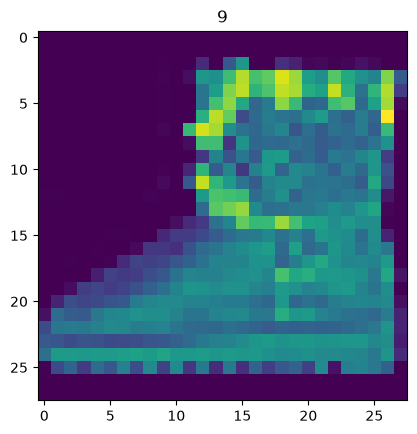

In [650]:
plt.imshow((x_train.iloc[12].to_numpy().reshape(28,28)))
plt.title(y_train.iloc[12])
plt.show()

In [651]:
y_train.describe()

count    60000.000000
mean         4.500000
std          2.872305
min          0.000000
25%          2.000000
50%          4.500000
75%          7.000000
max          9.000000
Name: label, dtype: float64

In [652]:
X=x_train.to_numpy()
Y=y_train.to_numpy()
x_test=x_test.to_numpy()
y_test=y_test.to_numpy()

In [653]:
keys=np.arange(X.shape[0])
np.random.shuffle(keys)
X=X[keys]
Y=Y[keys]

In [654]:
model=Model()

In [655]:
model.add(Dense_Layer(n_inputs=X.shape[1],n_neurons=128,weights_regularizer_l1=5e-4,weights_regularizer_l2=5e-4))
model.add(Activation_Relu())
model.add(Dense_Layer(n_inputs=128,n_neurons=128,weights_regularizer_l1=5e-5,weights_regularizer_l2=5e-4))
model.add(Activation_Relu())
model.add(Dense_Layer(n_inputs=128,n_neurons=10))
model.add(Activation_Softmax())

In [656]:
model.set(loss=Loss_CategoricalCrossentropy(),optimizer=Optimizer_Adam(decay=1e-4),accuracy=Accuracy_Categorical())

In [657]:
model.finalize()

In [658]:
#Train the model
model.train(X,Y,validation_data=(x_test,y_test),epoch=10,batch_size=128,print_interval=100)

#Print the paarameters that we have got by training
parameters=model.get_parameter()
print(parameters)

epoch:1
step: 0, acc: 0.094, loss:2.716(data_loss:2.303, reg_loss: 0.413), lr: 0.001
step: 100, acc: 0.711, loss:0.963(data_loss:0.704, reg_loss: 0.260), lr: 0.0009900990099009901
step: 200, acc: 0.852, loss:0.736(data_loss:0.516, reg_loss: 0.220), lr: 0.000980392156862745
step: 300, acc: 0.773, loss:0.802(data_loss:0.593, reg_loss: 0.209), lr: 0.0009708737864077671
step: 400, acc: 0.766, loss:0.887(data_loss:0.683, reg_loss: 0.204), lr: 0.0009615384615384615
step: 468, acc: 0.823, loss:0.639(data_loss:0.450, reg_loss: 0.189), lr: 0.0009552923194497518
training,acc: 0.731, loss:0.936(data_loss:0.747, reg_loss: 0.189), lr: 0.0009552923194497518
validation,acc:0.801,loss:0.540
epoch:2
step: 0, acc: 0.820, loss:0.651(data_loss:0.462, reg_loss: 0.189), lr: 0.0009552010698251983
step: 100, acc: 0.828, loss:0.634(data_loss:0.446, reg_loss: 0.188), lr: 0.0009461633077869241
step: 200, acc: 0.883, loss:0.567(data_loss:0.389, reg_loss: 0.178), lr: 0.0009372949667260287
step: 300, acc: 0.773, lo

In [659]:
model=Model()

In [660]:
model.add(Dense_Layer(n_inputs=X.shape[1],n_neurons=128,weights_regularizer_l1=5e-4,weights_regularizer_l2=5e-4))
model.add(Activation_Relu())
model.add(Dense_Layer(n_inputs=128,n_neurons=128,weights_regularizer_l1=5e-5,weights_regularizer_l2=5e-4))
model.add(Activation_Relu())
model.add(Dense_Layer(n_inputs=128,n_neurons=10))
model.add(Activation_Softmax())

In [661]:
model.set(loss=Loss_CategoricalCrossentropy(),accuracy=Accuracy_Categorical())

In [662]:
model.finalize()

In [663]:
model.set_parameter(parameters)

In [664]:
model.evaluate(x_test,y_test)

validation,acc:0.857,loss:0.391


In [665]:
model.save_parameter('fashion_mnist.parms')

In [666]:
model.save('fashion_mnist.model')

In [667]:
model=Model.load('fashion_mnist.model')

In [668]:
model.evaluate(x_test,y_test)

validation,acc:0.857,loss:0.391


In [669]:
model=Model.load('fashion_mnist.model')

In [676]:
confidences=model.predict(x_test[2000:2010])

In [677]:
print(confidences)

[[3.38168142e-04 1.47342168e-06 3.39928173e-03 7.89735354e-04
  3.56615951e-03 1.82231579e-04 1.25178189e-03 9.09186954e-07
  9.90469848e-01 4.10807619e-07]
 [8.26007228e-05 4.85737724e-05 1.65928564e-04 5.25656164e-05
  1.00718016e-05 9.92654609e-01 4.77664334e-05 5.96510630e-03
  7.52497253e-04 2.20280461e-04]
 [1.89225809e-01 1.08700430e-03 2.21993227e-03 7.07295206e-01
  8.78157501e-03 3.84761828e-07 8.71408363e-02 2.36392477e-09
  4.24921627e-03 3.32968288e-08]
 [4.65461307e-05 2.47195487e-05 3.35054121e-02 3.38085274e-05
  9.09805324e-01 1.34519395e-08 5.63911524e-02 5.12739667e-11
  1.93011693e-04 1.23419586e-08]
 [1.04641828e-07 7.55782385e-07 9.15692045e-08 5.86309720e-07
  1.58128048e-08 2.17726241e-03 9.83940135e-08 2.32827407e-02
  7.59088887e-05 9.74462436e-01]
 [4.72886684e-04 9.71458135e-06 3.54391999e-05 2.57099506e-05
  4.53984959e-06 9.70368653e-01 2.85166241e-04 8.06100127e-03
  4.29631564e-03 1.64405731e-02]
 [5.37234775e-03 8.01297991e-05 5.32867087e-03 1.00324331e

In [678]:
predictions=model.output_layer_activation.predictions(confidences)

In [679]:
print(predictions)

[8 5 3 4 9 5 8 7 6 4]


In [681]:
y_test[2000:2010]

array([8, 5, 3, 4, 9, 5, 8, 7, 6, 4])

In [675]:
names = ['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

In [683]:
for p, t in zip(predictions[:10], y_test[2000:2010]):
    print(f'predicted: {names[p]:12} | actual: {names[t]}')

predicted: Bag          | actual: Bag
predicted: Sandal       | actual: Sandal
predicted: Dress        | actual: Dress
predicted: Coat         | actual: Coat
predicted: Ankle boot   | actual: Ankle boot
predicted: Sandal       | actual: Sandal
predicted: Bag          | actual: Bag
predicted: Sneaker      | actual: Sneaker
predicted: Shirt        | actual: Shirt
predicted: Coat         | actual: Coat
